Saved to chapters/BatteryDischarge.pdf


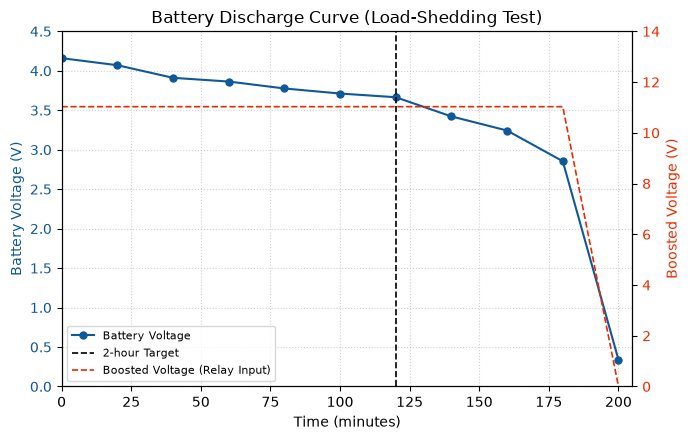

In [3]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# --- 1. Your Real Data ---
time_min = np.array([0, 20, 40, 60, 80, 100, 120, 140, 160, 180, 200])
battery_v = np.array([4.160, 4.071, 3.911, 3.864, 3.776, 3.712, 3.665, 3.422, 3.243, 2.854, 0.340])

# Boosted voltage at relay input (drops to 0 at 180 mins)
boosted_v = np.array([11.03, 11.03, 11.03, 11.03, 11.03, 11.03, 11.03, 11.03, 11.03, 11.03, 0.0])

# The 2-hour acceptance criterion
crit_time = 120

# --- 2. Create the Plot ---
fig, ax1 = plt.subplots(figsize=(7, 4.5))

# Plot Battery Voltage (Left Axis)
color1 = '#0f5899' # Dark blue
ax1.set_xlabel('Time (minutes)')
ax1.set_ylabel('Battery Voltage (V)', color=color1)
ax1.plot(time_min, battery_v, '-o', color=color1, linewidth=1.5, markersize=5, label='Battery Voltage')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.set_ylim(0, 4.5)
ax1.grid(True, linestyle=':', alpha=0.6)

# Add the 2-hour criterion line
ax1.axvline(crit_time, color='black', linestyle='--', linewidth=1.2, label='2-hour Target')

# Set x-axis limits
ax1.set_xlim(0, 205)

# Create a second y-axis for the Boosted Voltage (Right Axis)
ax2 = ax1.twinx()
color2 = "#ea2b00" # Rust/orange
ax2.set_ylabel('Boosted Voltage (V)', color=color2)
ax2.plot(time_min, boosted_v, '--', color=color2, linewidth=1.2, label='Boosted Voltage (Relay Input)')
ax2.tick_params(axis='y', labelcolor=color2)
ax2.set_ylim(0, 14)

# --- 3. Combine Legends ---
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='lower left', fontsize=8)

plt.title('Battery Discharge Curve (Load-Shedding Test)')
plt.tight_layout()

# --- 4. Save ---
out_dir = Path('chapters')
out_dir.mkdir(exist_ok=True)
plt.savefig(out_dir / 'BatteryDischarge.pdf')
print("Saved to chapters/BatteryDischarge.pdf")

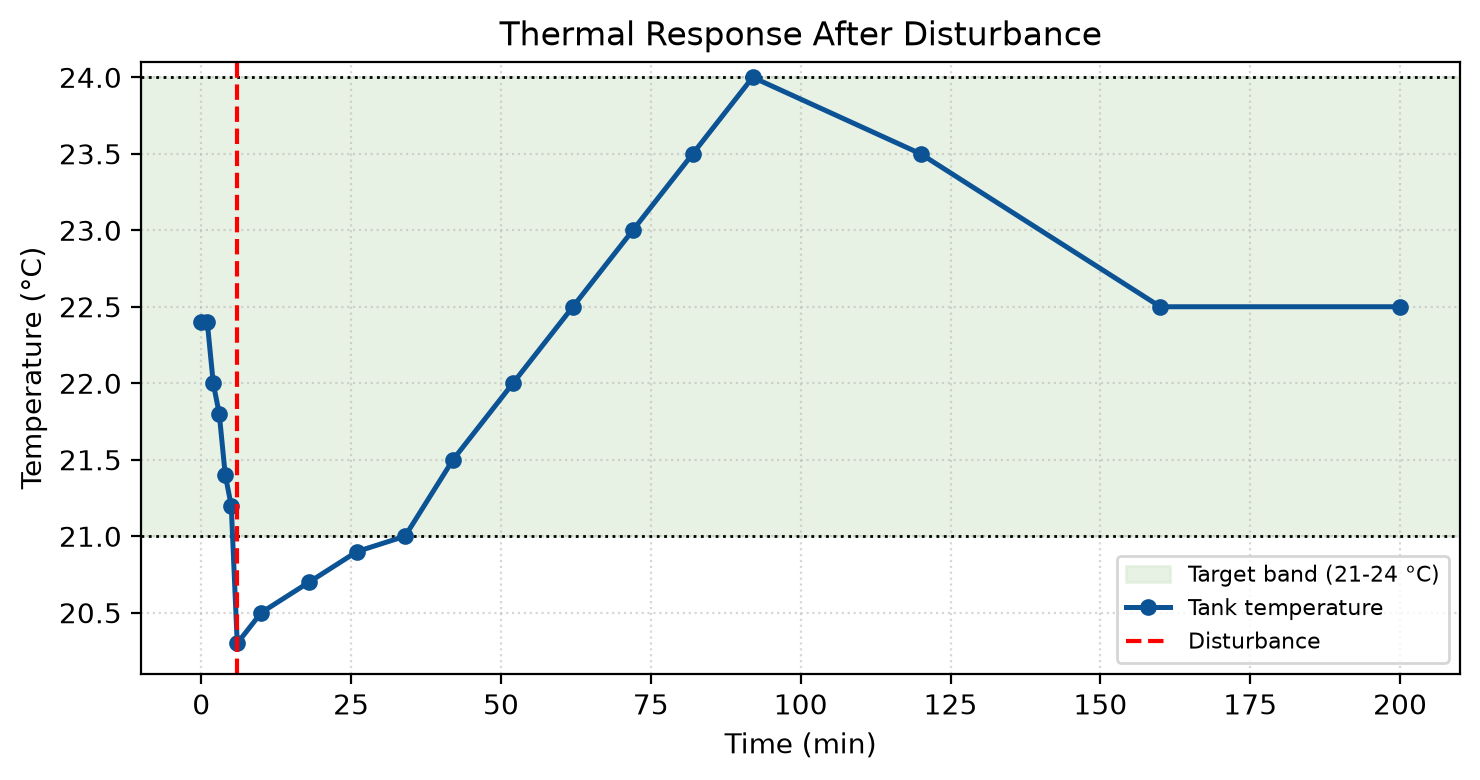

In [ ]:
import matplotlib.pyplot as plt

# Time (min) and tank temperature (°C)
t = [0, 1, 2, 3, 4, 5, 6, 10, 18, 26, 34, 42, 52, 62, 72, 82, 92, 120, 160, 200]
T = [22.4, 22.4, 22.0, 21.8, 21.4, 21.2, 20.3, 20.5, 20.7, 20.9, 21.0,
     21.5, 22.0, 22.5, 23.0, 23.5, 24.0, 23.5, 22.5, 22.5]

t_dist = 6          # time of the disturbance (min)
low, high = 21, 24  # target band (°C)

fig, ax = plt.subplots(figsize=(7.5, 4.0), dpi=200)

# Target band and its limits
ax.axhspan(low, high, color="#d9ead3", alpha=0.6, label="Target band (21-24 °C)")
ax.axhline(low, color="black", linestyle=":", linewidth=1)
ax.axhline(high, color="black", linestyle=":", linewidth=1)

# Measured temperature
ax.plot(t, T, marker="o", markersize=5, linewidth=1.8,
        color="#0b5394", label="Tank temperature")

# Disturbance marker
ax.axvline(t_dist, color="red", linestyle="--", linewidth=1.5, label="Disturbance")

ax.set_title("Thermal Response After Disturbance")
ax.set_xlabel("Time (min)")
ax.set_ylabel("Temperature (°C)")
ax.set_xlim(-10, 210)
ax.set_ylim(20.1, 24.1)
ax.set_xticks(range(0, 201, 25))
ax.set_yticks([20.5, 21.0, 21.5, 22.0, 22.5, 23.0, 23.5, 24.0])
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend(loc="lower right", fontsize=8)

fig.tight_layout()
fig.savefig("ThermalResponse.pdf")                # vector, best for LaTeX
fig.savefig("ThermalResponse.png", dpi=300)       # raster copy
plt.show()